# SmartFactory AI - Etape 2 : PCA (réduction de dimension)
Prérequis : avoir exécuté le notebook 01 (fichiers `train.csv`, `test.csv`, `feature_cols.pkl`).
Règle importante : la PCA est **ajustée sur le train uniquement**, puis appliquée au test.

## 1. Imports et chargement

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
feature_cols = joblib.load("models/feature_cols.pkl")

X_train, y_train = train[feature_cols], train["target"]
X_test, y_test = test[feature_cols], test["target"]
print(X_train.shape, X_test.shape)

(8000, 9) (2000, 9)


## 2. PCA complète : variance expliquée
On garde toutes les composantes pour voir combien d'information porte chacune.

In [2]:
pca_full = PCA(random_state=42).fit(X_train)

var = pca_full.explained_variance_ratio_
cum = np.cumsum(var)

table = pd.DataFrame({
    "Composante": [f"PC{i+1}" for i in range(len(var))],
    "Variance expliquée (%)": (var * 100).round(2),
    "Cumulée (%)": (cum * 100).round(2),
})
display(table)

n_90 = int(np.argmax(cum >= 0.90) + 1)
n_95 = int(np.argmax(cum >= 0.95) + 1)
print(f"Composantes pour 90 % de variance : {n_90}")
print(f"Composantes pour 95 % de variance : {n_95}")

,Composante,Variance expliquée (%),Cumulée (%)
0,PC1,33.44,33.44
1,PC2,25.15,58.59
2,PC3,19.29,77.88
3,PC4,11.10,88.98
4,PC5,8.19,97.17
5,PC6,2.39,99.56
6,PC7,0.31,99.87
7,PC8,0.13,100.00
8,PC9,0.00,100.00


Composantes pour 90 % de variance : 5
Composantes pour 95 % de variance : 5


### Scree plot (éboulis) et variance cumulée

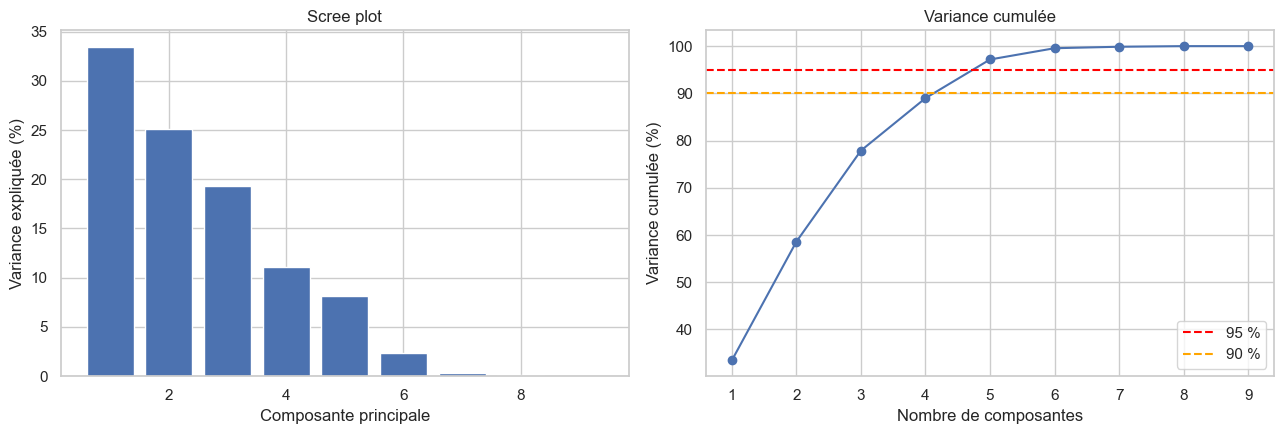

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(range(1, len(var) + 1), var * 100)
axes[0].set_xlabel("Composante principale")
axes[0].set_ylabel("Variance expliquée (%)")
axes[0].set_title("Scree plot")

axes[1].plot(range(1, len(cum) + 1), cum * 100, marker="o")
axes[1].axhline(95, color="red", linestyle="--", label="95 %")
axes[1].axhline(90, color="orange", linestyle="--", label="90 %")
axes[1].set_xlabel("Nombre de composantes")
axes[1].set_ylabel("Variance cumulée (%)")
axes[1].set_title("Variance cumulée")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Interprétation des composantes (loadings)
Un loading indique **combien chaque variable d'origine contribue** à une composante. Plus il est grand en valeur absolue, plus la variable compte.

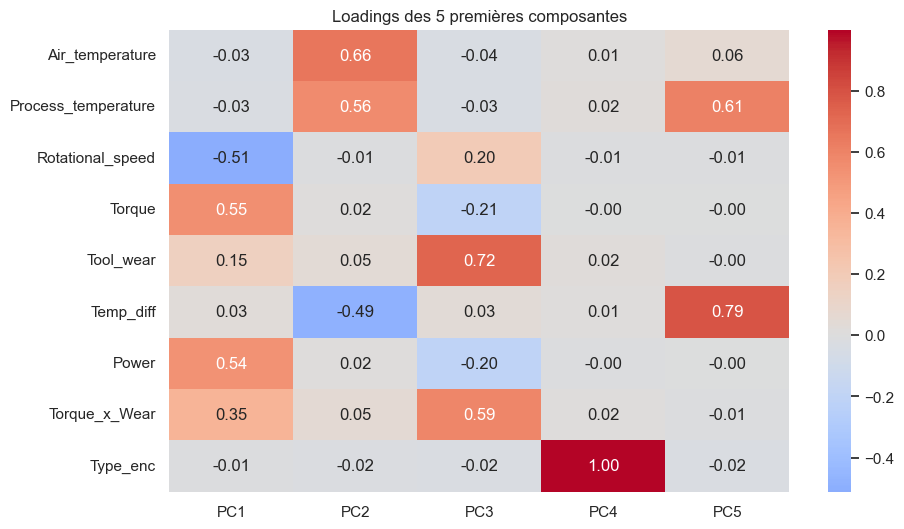


Variables les plus contributives à PC1 :
Torque              0.549
Power               0.536
Rotational_speed    0.512
Name: PC1, dtype: float64

Variables les plus contributives à PC2 :
Air_temperature        0.662
Process_temperature    0.564
Temp_diff              0.488
Name: PC2, dtype: float64

Variables les plus contributives à PC3 :
Tool_wear        0.725
Torque_x_Wear    0.591
Torque           0.205
Name: PC3, dtype: float64


In [4]:
loadings = pd.DataFrame(
    pca_full.components_.T,
    index=feature_cols,
    columns=[f"PC{i+1}" for i in range(len(feature_cols))],
)

plt.figure(figsize=(10, 6))
sns.heatmap(loadings.iloc[:, :5], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Loadings des 5 premières composantes")
plt.show()

for pc in ["PC1", "PC2", "PC3"]:
    print(f"\nVariables les plus contributives à {pc} :")
    print(loadings[pc].abs().sort_values(ascending=False).head(3).round(3))

## 4. Projection 2D : les machines dans le plan PC1 - PC2

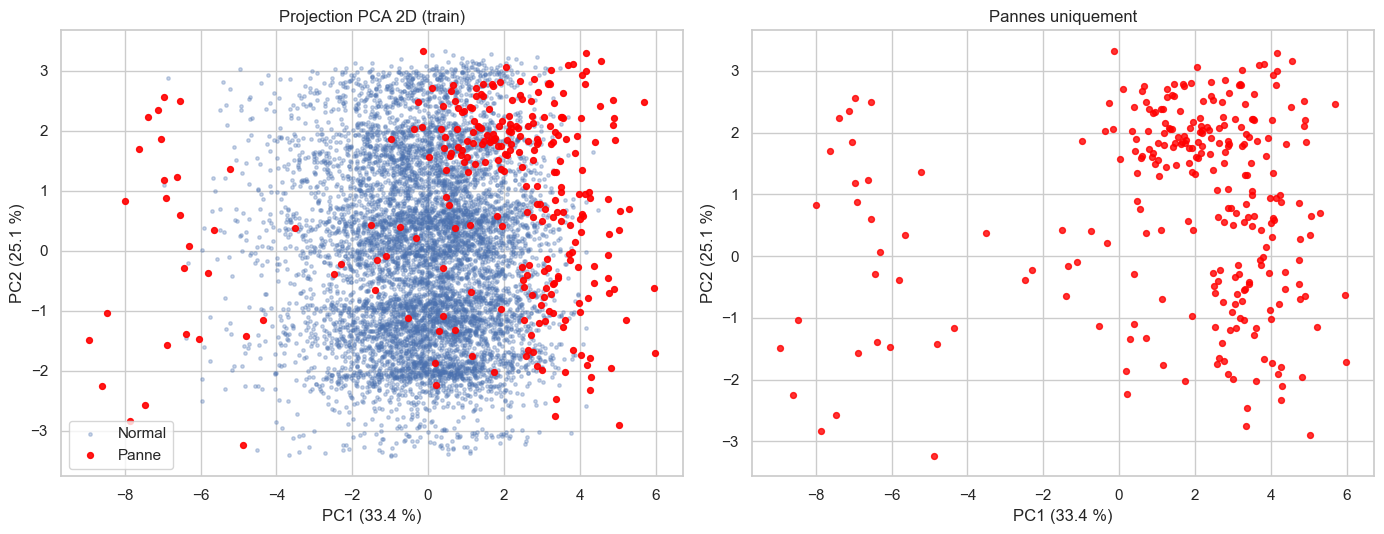

Variance expliquée par PC1+PC2 : 58.6 %


In [5]:
pca2 = PCA(n_components=2, random_state=42).fit(X_train)
Z_train = pca2.transform(X_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Toutes les machines
mask0 = (y_train == 0).values
mask1 = (y_train == 1).values
axes[0].scatter(Z_train[mask0, 0], Z_train[mask0, 1], s=6, alpha=0.3, label="Normal")
axes[0].scatter(Z_train[mask1, 0], Z_train[mask1, 1], s=18, alpha=0.9, color="red", label="Panne")
axes[0].set_title("Projection PCA 2D (train)")

# Zoom sur les pannes seules
axes[1].scatter(Z_train[mask1, 0], Z_train[mask1, 1], s=18, color="red", alpha=0.8)
axes[1].set_title("Pannes uniquement")

for ax in axes:
    ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f} %)")
    ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f} %)")
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"Variance expliquée par PC1+PC2 : {pca2.explained_variance_ratio_.sum()*100:.1f} %")

## 5. Cercle des corrélations (biplot des variables)

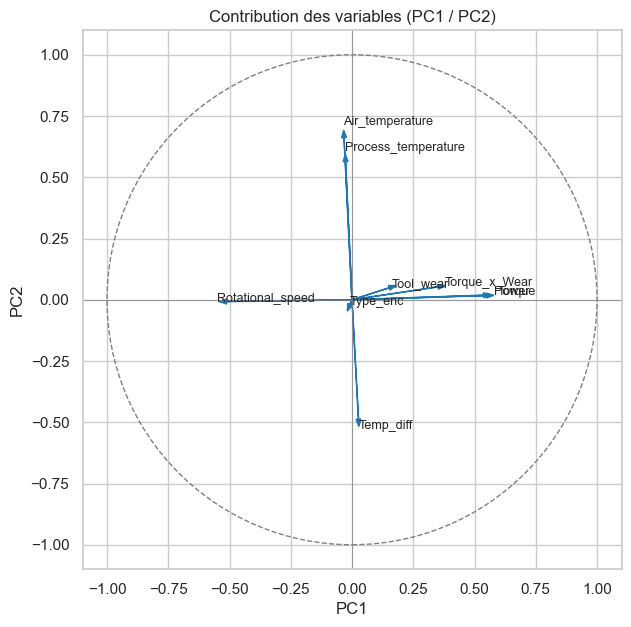

In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
for i, name in enumerate(feature_cols):
    x, y_ = pca2.components_[0, i], pca2.components_[1, i]
    ax.arrow(0, 0, x, y_, head_width=0.02, color="tab:blue")
    ax.text(x * 1.08, y_ * 1.08, name, fontsize=9)
circle = plt.Circle((0, 0), 1, fill=False, linestyle="--", color="gray")
ax.add_patch(circle)
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("Contribution des variables (PC1 / PC2)")
ax.set_aspect("equal")
plt.show()

## 6. Projection 3D interactive (optionnel)
Nécessite `pip install plotly`. Utile pour le dashboard.

In [7]:
import plotly.express as px

pca3 = PCA(n_components=3, random_state=42).fit(X_train)
Z3 = pca3.transform(X_train)
df3 = pd.DataFrame(Z3, columns=["PC1", "PC2", "PC3"])
df3["Etat"] = np.where(y_train.values == 1, "Panne", "Normal")

fig = px.scatter_3d(df3, x="PC1", y="PC2", z="PC3", color="Etat",
                    color_discrete_map={"Normal": "lightblue", "Panne": "red"},
                    opacity=0.6, title="PCA 3D")
fig.update_traces(marker_size=2)
fig.show()

## 7. Choix du nombre de composantes et sauvegarde
On retient le nombre de composantes qui conserve **95 %** de la variance.
Ces données serviront à comparer les modèles *avec* et *sans* PCA (étape 6 de l'énoncé).

In [8]:
pca = PCA(n_components=n_95, random_state=42).fit(X_train)

cols_pc = [f"PC{i+1}" for i in range(n_95)]
X_train_pca = pd.DataFrame(pca.transform(X_train), columns=cols_pc)
X_test_pca = pd.DataFrame(pca.transform(X_test), columns=cols_pc)

print(f"{n_95} composantes retenues, variance conservée : {pca.explained_variance_ratio_.sum()*100:.2f} %")

joblib.dump(pca, "models/pca.pkl")
X_train_pca.assign(target=y_train.values).to_csv("data/train_pca.csv", index=False)
X_test_pca.assign(target=y_test.values).to_csv("data/test_pca.csv", index=False)
print("Sauvegarde terminée.")

5 composantes retenues, variance conservée : 97.17 %
Sauvegarde terminée.


## Résumé à retenir pour le rapport
1. La PCA est ajustée sur le train, puis appliquée au test (pas de fuite).
2. Le scree plot et la variance cumulée justifient le nombre de composantes retenues.
3. Les loadings expliquent ce que représente chaque composante (par ex. « axe puissance/couple », « axe thermique »).
4. La projection 2D montre si les pannes sont séparables visuellement. Si elles sont mélangées avec les machines normales, c'est un résultat à discuter : la panne dépend de **combinaisons non linéaires** que la PCA (linéaire) ne capte pas.
5. Les variables construites (`Power`, `Torque_x_Wear`) sont corrélées à leurs variables d'origine, ce qui concentre la variance sur peu de composantes.